In [1]:
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath('')), 'Utilities'))
import numpy as np
import matplotlib.pyplot as plt
from hyperillumination_utils import *
from lightcurve_utils import *
from kepler_utils import *

In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.02                                   #planet radius [stellar radii / rs]
rs = 0.68                                   # stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]   
a = AU_to_RS(a_AU, rs)                      #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142e-6                                 #planet-to-star flux ratio / eclipse depth (integrated day-side flux)
T_eff = 4570                                # stellar effective temperature [K]

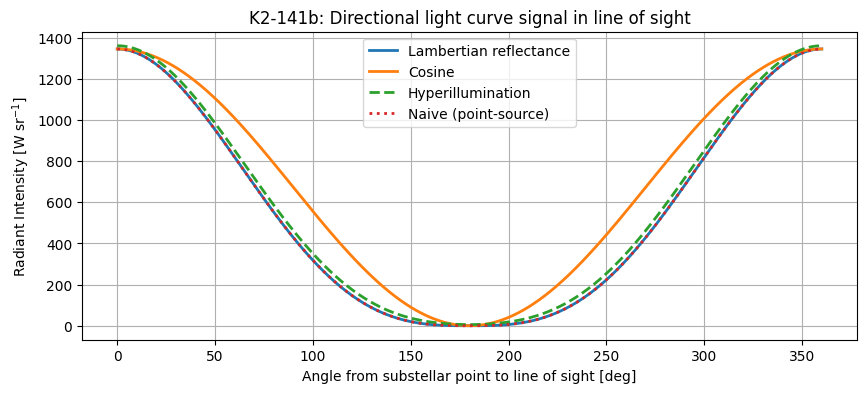

In [7]:
epsilon = np.linspace(0, 360, 1000)

L_kopal = reflected_lightcurve(np.radians(epsilon), rp, 1, a, T_eff, insolation_model="kopal")
L_naive = reflected_lightcurve(np.radians(epsilon), rp, 1, a, T_eff, insolation_model="naive")
L_cos = (np.cos(np.radians(epsilon))+1)/2*np.max(L_naive)
L_lambertian = lambertian_reflectance(np.radians(epsilon), rp, 1, a, T_eff)

plt.figure(figsize=(10, 4))
plt.plot(epsilon, L_lambertian, linewidth=2, label="Lambertian reflectance")
plt.plot(epsilon, L_cos, linewidth=2, label="Cosine")
plt.plot(epsilon, L_kopal, linewidth=2, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive, linewidth=2, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Radiant Intensity [W sr$^{-1}$]")
plt.title("K2-141b: Directional light curve signal in line of sight")
plt.legend()
plt.grid()

In [4]:
np.max(L_lambertian)/np.max(L_naive)

np.float64(0.9999999999999928)